# 01 · CRAG part 1: retrieval evaluator + the CORRECT path


## where I am

From 00:
- out of corpus questions give "I don't know" (strict prompt) or answers from the model's memory (loose prompt)
- half covered questions leak even with the strict prompt. XGBoost isn't in my books at all and the answer still described it

The paper's fix is simple to say: check the retrieved docs before using them.

## what I'm building here

1. the retrieval evaluator and action trigger (sections 4.2 and 4.3). score every (question, chunk) pair, then decide CORRECT / INCORRECT / AMBIGUOUS
2. knowledge refinement (section 4.4). for the CORRECT case, cut the good chunks down to only the useful sentences
3. INCORRECT and AMBIGUOUS just stop for now, those are 02 and 03

```
START → retrieve → evaluate ─┬─ CORRECT   → refine → generate → END
                             ├─ INCORRECT → (stub) → END
                             └─ AMBIGUOUS → (stub) → END
```

## setup

Loading the FAISS index from 00, so no pdf loading and no embedding cost.

In [4]:
import os
import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)  # langchain-community sunset notice
from pathlib import Path
from typing import Literal, TypedDict

from dotenv import load_dotenv
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

INDEX_DIR = PROJECT_ROOT / "vectorstore" / "faiss_index"
assert INDEX_DIR.exists(), "Run 00_simple_rag.ipynb first to build the FAISS index."

embeddings = OpenAIEmbeddings(model=os.environ["OPENAI_EMBEDDING_MODEL"])
vectorstore = FAISS.load_local(str(INDEX_DIR), embeddings, allow_dangerous_deserialization=True)
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})
llm = ChatOpenAI(model=os.environ["OPENAI_CHAT_MODEL"], temperature=0)

TEST_QUERIES = {
    "in_corpus": "Explain the bias-variance trade-off.",
    "recent": "What were the top AI news stories in the last month?",
    "out_of_corpus": "What is the transformer architecture in deep learning?",
    "partial": "Compare support vector machines with XGBoost for tabular data.",
}

print(f"Loaded {vectorstore.index.ntotal} vectors")

Loaded 5933 vectors


---
# part A: the retrieval evaluator

## what the paper says (sections 4.2 and 4.3)

A small model looks at the question and one retrieved doc at a time and gives a relevance score. Then two thresholds
turn those scores into one verdict for the whole retrieval:

- CORRECT: at least one doc scores above the upper threshold. use the docs (after refining them)
- INCORRECT: every doc scores below the lower threshold. throw them away and search the web
- AMBIGUOUS: anything in between. use both

Another detail I almost missed: only docs above the lower threshold get used for generation. So even when the verdict
is CORRECT, a doc that scored 0.2 gets dropped. I'm calling the kept ones `good_docs`.

The paper uses a fine-tuned T5-large (0.77B params) as the evaluator and says it does better than ChatGPT at this. The
weights aren't released, so I'm just prompting gpt-4o-mini. It works, but now every chunk costs an LLM call.

About the thresholds. In the paper the evaluator scores from -1 to 1 and the thresholds were set empirically per
dataset (appendix B.3). For PopQA it's upper 0.59 and lower -0.99. On my 0 to 1 scale that's roughly 0.8 and 0.005, so
in the paper INCORRECT only fires when the docs are basically certainly irrelevant, and a lot ends up AMBIGUOUS.
Those numbers are tuned to their T5's scores though, not gpt-4o-mini's. So I'm starting with 0.3 / 0.7 and checking
how sensitive things are at the end.

In [5]:
LOWER_THRESHOLD = 0.3
UPPER_THRESHOLD = 0.7

## step 1: verdict logic first (no LLM)

Writing the decision rule as a plain function and testing it on a few made up score lists. If this part is wrong
nothing after it will be right.

In [6]:
Verdict = Literal["CORRECT", "INCORRECT", "AMBIGUOUS"]


def decide_verdict(scores: list[float], lower: float = LOWER_THRESHOLD, upper: float = UPPER_THRESHOLD) -> tuple[Verdict, str]:
    if any(s > upper for s in scores):
        return "CORRECT", f"At least one chunk scored above {upper}."
    if all(s < lower for s in scores):
        return "INCORRECT", f"All chunks scored below {lower}."
    return "AMBIGUOUS", f"No chunk scored above {upper}, but not all were below {lower}."


def good_doc_indices(scores: list[float], lower: float = LOWER_THRESHOLD) -> list[int]:
    return [i for i, s in enumerate(scores) if s > lower]


# a few hand made cases
assert decide_verdict([0.8, 0.5])[0] == "CORRECT"
assert decide_verdict([0.1, 0.2])[0] == "INCORRECT"
assert decide_verdict([0.55, 0.5])[0] == "AMBIGUOUS"
assert decide_verdict([0.8, 0.4, 0.2])[0] == "CORRECT"
assert good_doc_indices([0.8, 0.4, 0.2]) == [0, 1]  # CORRECT, but d3 (0.2) is still dropped
print("verdict logic ✓")

verdict logic ✓


## step 2: the LLM evaluator

Using structured output (a pydantic schema) so the LLM has to return a `score` and a short `reason`. The reason turns
out to be really useful for debugging, see below.

In [7]:
class ChunkEvaluation(BaseModel):
    score: float = Field(description="Relevance score between 0.0 and 1.0")
    reason: str = Field(description="One short sentence explaining the score")


evaluator_prompt_v1 = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict retrieval evaluator for a RAG system. You are given a question and ONE retrieved chunk.\n"
     "Return a relevance score between 0.0 and 1.0:\n"
     "- 1.0 = the chunk alone is sufficient to fully or mostly answer the question\n"
     "- 0.0 = the chunk is irrelevant to the question\n"
     "Be conservative with high scores. Give a one-sentence reason."),
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])

evaluator_chain = evaluator_prompt_v1 | llm.with_structured_output(ChunkEvaluation)


def evaluate_docs(question: str, docs: list[Document]) -> list[ChunkEvaluation]:
    # .batch() sends the calls in parallel instead of one by one
    inputs = [{"question": question, "chunk": d.page_content} for d in docs]
    results = evaluator_chain.batch(inputs, config={"max_concurrency": 8})
    for r in results:
        r.score = min(max(r.score, 0.0), 1.0)  # clamp, just in case
    return results


def describe(doc: Document) -> str:
    return f"{Path(doc.metadata.get('source', '?')).name[:22]} p.{doc.metadata.get('page', '?')}"

### trying the evaluator on its own

Before putting it in a graph, I want to see what it says about the chunks for each test question. These are the same
chunks plain RAG used in 00.

In [8]:
def inspect_evaluator() -> dict[str, list[float]]:
    all_scores = {}
    for key, question in TEST_QUERIES.items():
        docs = retriever.invoke(question)
        evals = evaluate_docs(question, docs)
        all_scores[key] = [e.score for e in evals]
        verdict, reason = decide_verdict(all_scores[key])

        print(f"\n{'=' * 90}\n[{key}] {question}\n→ {verdict}: {reason}")
        for i, (d, e) in enumerate(zip(docs, evals), 1):
            print(f"  d{i} {e.score:.2f}  {describe(d):<30} {e.reason}")
    return all_scores


scores_v1 = inspect_evaluator()


[in_corpus] Explain the bias-variance trade-off.
→ CORRECT: At least one chunk scored above 0.7.
  d1 0.30  ISLP_website.pdf p.47          The chunk mentions the bias-variance tradeoff but does not explain it.
  d2 0.80  ISLP_website.pdf p.43          The chunk provides a good explanation of the bias-variance trade-off but does not fully define the concepts of bias and variance.
  d3 1.00  ISLP_website.pdf p.43          The chunk provides a clear explanation of the bias-variance trade-off, including its implications for model performance.
  d4 0.70  Bishop-Pattern-Recogni p.166   The chunk introduces the bias-variance trade-off but does not fully explain it.

[recent] What were the top AI news stories in the last month?
→ INCORRECT: All chunks scored below 0.3.
  d1 0.00  ISLP_website.pdf p.405         The chunk does not address any specific AI news stories from the last month.
  d2 0.00  ISLP_website.pdf p.405         The chunk does not provide any information about recent AI news st

What I expected:
- `in_corpus` should have at least one chunk clearly above 0.7, so CORRECT
- `recent` and `out_of_corpus` chunks are general deep learning stuff, the evaluator should see they don't answer anything
- `partial` SVM chunks should get some credit since they cover half the question

### problem with `partial`

In my run every SVM chunk scored 0.0 to 0.2 and the verdict was INCORRECT. The reasons say things like "only discusses
SVMs without any comparison to XGBoost". So my v1 prompt is basically asking "can this chunk answer the whole question?"
and a chunk that covers half of a comparison gets nothing.

That's not what the paper's evaluator does. It scores relevance, how useful the doc is. If half useful counts as
useless, the AMBIGUOUS path never happens and every question like this goes straight to the web, throwing away good
SVM material from the books.

### fix: v2 prompt with a scoring rubric

Giving it explicit score ranges, including one for "answers part of the question". I also put "same broad topic but
not useful" at 0.1-0.2 so it stays under the lower threshold, otherwise CNN chunks for the transformer question might
sneak into AMBIGUOUS.

In [10]:
evaluator_prompt_v2 = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict retrieval evaluator for a RAG system. You are given a question and ONE retrieved chunk.\n"
     "Score how useful the chunk is for answering the question, between 0.0 and 1.0:\n"
     "- 0.8-1.0: directly and substantially answers the question (or its main part)\n"
     "- 0.4-0.7: answers PART of the question (e.g. covers one of the things being compared) or gives a key piece of the answer\n"
     "- 0.1-0.2: same broad topic, but contains nothing that helps answer this question\n"
     "- 0.0: unrelated\n"
     "Be conservative with high scores. Give a one-sentence reason."),
    ("human", "Question: {question}\n\nChunk:\n{chunk}"),
])

evaluator_chain = evaluator_prompt_v2 | llm.with_structured_output(ChunkEvaluation)  # evaluate_docs now uses v2
eval_cache = inspect_evaluator()  # keep the v2 scores for the threshold experiment at the end


[in_corpus] Explain the bias-variance trade-off.
→ CORRECT: At least one chunk scored above 0.7.
  d1 0.10  ISLP_website.pdf p.47          The chunk mentions the bias-variance tradeoff but does not explain it or provide any details.
  d2 0.80  ISLP_website.pdf p.43          The chunk directly discusses the bias-variance trade-off, explaining the concepts of high variance and low bias, which are central to understanding the trade-off.
  d3 0.80  ISLP_website.pdf p.43          The chunk directly explains the bias-variance trade-off and its implications for model performance.
  d4 0.40  Bishop-Pattern-Recogni p.166   The chunk introduces the bias-variance trade-off but does not explain what it is or how it works.

[recent] What were the top AI news stories in the last month?
→ INCORRECT: All chunks scored below 0.3.
  d1 0.10  ISLP_website.pdf p.405         The chunk discusses the history and evolution of neural networks but does not provide any information about recent AI news stories.


In [11]:
print(f"{'query':<15}{'v1 scores':<28}{'v1 verdict':<12}{'v2 scores':<28}{'v2 verdict'}")
for key in TEST_QUERIES:
    v1, v2 = scores_v1[key], eval_cache[key]
    print(f"{key:<15}{str([round(x, 2) for x in v1]):<28}{decide_verdict(v1)[0]:<12}"
          f"{str([round(x, 2) for x in v2]):<28}{decide_verdict(v2)[0]}")

query          v1 scores                   v1 verdict  v2 scores                   v2 verdict
in_corpus      [0.3, 0.8, 1.0, 0.7]        CORRECT     [0.1, 0.8, 0.8, 0.4]        CORRECT
recent         [0.0, 0.0, 0.0, 0.0]        INCORRECT   [0.1, 0.0, 0.1, 0.1]        INCORRECT
out_of_corpus  [0.0, 0.0, 0.0, 0.0]        INCORRECT   [0.0, 0.0, 0.0, 0.0]        INCORRECT
partial        [0.0, 0.0, 0.0, 0.0]        INCORRECT   [0.4, 0.1, 0.1, 0.1]        AMBIGUOUS


So with an LLM as the evaluator, the prompt basically is the evaluator. The paper gets around this by fine-tuning T5
on labelled data. A rubric in the prompt is my cheap version of that.


---
# part B: knowledge refinement

## what the paper says (section 4.4)

Even a relevant chunk has junk in it. My splitter cuts every ~900 characters without caring about topics, so a
bias-variance chunk can also have half a paragraph about something else, figure captions, code, etc.

The paper calls the fix decompose-then-recompose:

1. decompose: split each doc into small "knowledge strips" (a sentence or two)
2. filter: check each strip against the question and drop the irrelevant ones
3. recompose: join what's left back together. that's the "internal knowledge"

They use the same fine-tuned T5 for the filtering, and keep the top 5 strips above a filter threshold (appendix B.3).
I'm doing something simpler, gpt-4o-mini with a yes/no answer per sentence.

## step 3: splitting into strips

The paper doesn't say exactly how to split, just a sentence or two per strip. PDF text has line breaks in the middle
of sentences, so first I squash the whitespace, then split on . ! ? and drop really short bits like page numbers or
`In [31]:`.

In [12]:
MIN_STRIP_CHARS = 25


def decompose_to_strips(text: str) -> list[str]:
    text = " ".join(text.split())  # undo PDF line breaks
    sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9(\"'])", text)
    return [s.strip() for s in sentences if len(s.strip()) >= MIN_STRIP_CHARS]


demo = ("Gradient descent is an optimization algorithm used to minimize a loss function. It iteratively updates "
        "parameters in the direction of the negative gradient.\nNeural networks are composed of layers of neurons "
        "with non-linear\nactivation functions. Convolutional neural networks are effective for image tasks.")
for i, s in enumerate(decompose_to_strips(demo), 1):
    print(f"strip {i}: {s}")

strip 1: Gradient descent is an optimization algorithm used to minimize a loss function.
strip 2: It iteratively updates parameters in the direction of the negative gradient.
strip 3: Neural networks are composed of layers of neurons with non-linear activation functions.
strip 4: Convolutional neural networks are effective for image tasks.


Quick sanity check with a made up chunk. If the question is "what is gradient descent?" then strips 1-2 should stay
and 3-4 should go.

## step 4: filtering strips with the LLM

In [13]:
class StripDecision(BaseModel):
    keep: bool = Field(description="True only if the sentence directly helps answer the question")


strip_filter_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a strict relevance filter. Return keep=true ONLY if the sentence directly helps answer the question. "
     "Judge the sentence on its own."),
    ("human", "Question: {question}\n\nSentence: {strip}"),
])

strip_filter_chain = strip_filter_prompt | llm.with_structured_output(StripDecision)


def filter_strips(question: str, strips: list[str]) -> list[bool]:
    inputs = [{"question": question, "strip": s} for s in strips]
    return [d.keep for d in strip_filter_chain.batch(inputs, config={"max_concurrency": 8})]


demo_strips = decompose_to_strips(demo)
for keep, s in zip(filter_strips("What is gradient descent?", demo_strips), demo_strips):
    print(("KEEP " if keep else "drop ") + s)

KEEP Gradient descent is an optimization algorithm used to minimize a loss function.
KEEP It iteratively updates parameters in the direction of the negative gradient.
drop Neural networks are composed of layers of neurons with non-linear activation functions.
drop Convolutional neural networks are effective for image tasks.


## step 5: the whole refine function

Refining each good doc separately like the paper does, and keeping track of which doc each strip came from so I can
show sources later.

In [14]:
def refine_docs(question: str, docs: list[Document]) -> dict:
    strips, sources = [], []
    for doc in docs:
        for s in decompose_to_strips(doc.page_content):
            strips.append(s)
            sources.append(describe(doc))

    keep_flags = filter_strips(question, strips) if strips else []
    kept = [(src, s) for src, s, k in zip(sources, strips, keep_flags) if k]

    return {
        "strips": strips,
        "kept_strips": [s for _, s in kept],
        "kept_sources": [src for src, _ in kept],
        "refined_context": "\n".join(s for _, s in kept),
    }


bv_question = TEST_QUERIES["in_corpus"]
bv_docs = retriever.invoke(bv_question)
refined = refine_docs(bv_question, bv_docs)

before = sum(len(d.page_content) for d in bv_docs)
after = len(refined["refined_context"])
print(f"strips kept: {len(refined['kept_strips'])}/{len(refined['strips'])}")
print(f"context size: {before:,} chars → {after:,} chars ({after / before:.0%})\n")
for src, s in zip(refined["kept_sources"], refined["kept_strips"]):
    print(f"  [{src}] {s}")

strips kept: 6/19
context size: 2,432 chars → 952 chars (39%)

  [ISLP_website.pdf p.43] high variance (for instance, by drawing a curve that passes through every single training observation) or a method with very low variance but high bias (by fitting a horizontal line to the data).
  [ISLP_website.pdf p.43] The challenge lies in finding a method for which both the variance and the squared bias are low.
  [ISLP_website.pdf p.43] Consequently, the test MSE declines substantially before experiencing a small increase as model flexibility increases.
  [ISLP_website.pdf p.43] The relationship between bias, variance, and test set MSE given in Equa- tion 2.7 and displayed in Figure 2.12 is referred to as the bias-variance trade-off.
  [ISLP_website.pdf p.43] Good test set performance of a statistical learning method re- bias-variance trade-offquires low variance as well as low squared bias.
  [ISLP_website.pdf p.43] This is referred to as a trade-off because it is easy to obtain a method wit

The refined context is less than half the size and almost all of it is on topic. Less noise for the generator and fewer tokens.

---
# part C: putting it in LangGraph

## state

A lot more fields than 00 now, for the evaluator output and the refinement steps. I like keeping the intermediate stuff in the state, then I can look at every step after a run.


In [15]:
class State(TypedDict):
    question: str
    docs: list[Document]          # raw retrieval (top-k)
    scores: list[float]           # evaluator score per doc
    score_reasons: list[str]
    good_docs: list[Document]     # docs scoring above LOWER_THRESHOLD
    verdict: Verdict
    reason: str
    strips: list[str]             # refinement: all strips
    kept_strips: list[str]        # refinement: strips that survived the filter
    kept_sources: list[str]
    refined_context: str          # recomposed internal knowledge
    answer: str

## nodes

In [16]:
def retrieve_node(state: State) -> dict:
    return {"docs": retriever.invoke(state["question"])}


def evaluate_node(state: State) -> dict:
    evals = evaluate_docs(state["question"], state["docs"])
    scores = [e.score for e in evals]
    verdict, reason = decide_verdict(scores)
    return {
        "scores": scores,
        "score_reasons": [e.reason for e in evals],
        "good_docs": [state["docs"][i] for i in good_doc_indices(scores)],
        "verdict": verdict,
        "reason": reason,
    }


def refine_node(state: State) -> dict:
    return refine_docs(state["question"], state["good_docs"])  # only good docs, never the raw top-k


answer_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a helpful ML tutor. Answer ONLY using the provided context. "
     "If the context is empty or insufficient, say: 'I don't know.'"),
    ("human", "Question: {question}\n\nContext:\n{context}"),
])


def generate_node(state: State) -> dict:
    out = (answer_prompt | llm).invoke({"question": state["question"], "context": state["refined_context"]})
    return {"answer": out.content}


# temporary dead ends: built properly in notebooks 02 and 03
def incorrect_stub_node(state: State) -> dict:
    return {"answer": "[INCORRECT] Retrieved documents can't answer this. (Web search comes in notebook 02.)"}


def ambiguous_stub_node(state: State) -> dict:
    return {"answer": "[AMBIGUOUS] Retrieved documents only partly answer this. (Handled in notebook 03.)"}


def route_after_eval(state: State) -> str:
    return {"CORRECT": "refine", "INCORRECT": "incorrect", "AMBIGUOUS": "ambiguous"}[state["verdict"]]

## graph

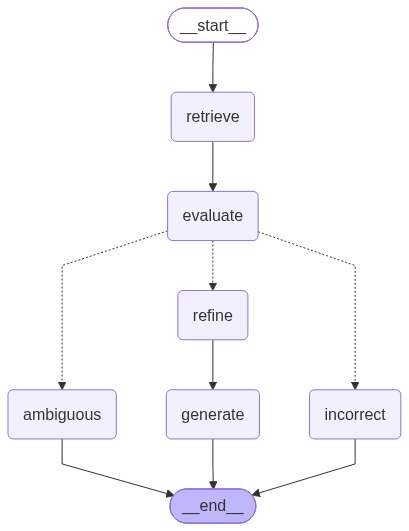

In [17]:
g = StateGraph(State)
g.add_node("retrieve", retrieve_node)
g.add_node("evaluate", evaluate_node)
g.add_node("refine", refine_node)
g.add_node("generate", generate_node)
g.add_node("incorrect", incorrect_stub_node)
g.add_node("ambiguous", ambiguous_stub_node)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "evaluate")
g.add_conditional_edges("evaluate", route_after_eval, {"refine": "refine", "incorrect": "incorrect", "ambiguous": "ambiguous"})
g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("incorrect", END)
g.add_edge("ambiguous", END)
app = g.compile()

from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:  # rendering needs internet (mermaid.ink); fall back to text
    print(app.get_graph().draw_mermaid())

---
# part D: testing

Same four questions as 00.

In [18]:
def run(key: str) -> dict:
    r = app.invoke({"question": TEST_QUERIES[key]})
    print(f"Q: {r['question']}\n")
    print(f"Verdict: {r['verdict']} ({r['reason']})")
    for i, (d, s, why) in enumerate(zip(r["docs"], r["scores"], r["score_reasons"]), 1):
        mark = "✓" if s > LOWER_THRESHOLD else "✗"
        print(f"  {mark} d{i} {s:.2f}  {describe(d):<30} {why}")
    if r["verdict"] == "CORRECT":
        raw = sum(len(d.page_content) for d in r["docs"])
        print(f"\nRefinement: kept {len(r['kept_strips'])}/{len(r['strips'])} strips, "
              f"{raw:,} → {len(r['refined_context']):,} chars")
    print(f"\nAnswer:\n{r['answer']}")
    return r

### in-corpus, expecting CORRECT

In [22]:
r_in = run("in_corpus")

Q: Explain the bias-variance trade-off.

Verdict: CORRECT (At least one chunk scored above 0.7.)
  ✗ d1 0.10  ISLP_website.pdf p.47          The chunk mentions the bias-variance tradeoff but does not explain what it is.
  ✓ d2 0.80  ISLP_website.pdf p.43          The chunk directly discusses the bias-variance trade-off, explaining the concepts of high variance and low bias, which are central to understanding the trade-off.
  ✓ d3 0.80  ISLP_website.pdf p.43          The chunk directly explains the bias-variance trade-off and its implications for model performance.
  ✓ d4 0.40  Bishop-Pattern-Recogni p.166   The chunk mentions the bias-variance trade-off but does not explain what it is or how it works.

Refinement: kept 7/17 strips, 2,432 → 1,057 chars

Answer:
The bias-variance trade-off refers to the balance between two types of errors that affect the performance of a statistical learning method: bias and variance. Bias is the error due to overly simplistic assumptions in the learning

Same quality answer as 00, but from a much smaller and cleaner context. And now the scores actually show the docs
were relevant.

### recent news, expecting INCORRECT

In [23]:
r_recent = run("recent")

Q: What were the top AI news stories in the last month?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.00  ISLP_website.pdf p.405         The chunk discusses the history and evolution of neural networks but does not provide any information about recent AI news stories.
  ✗ d2 0.00  ISLP_website.pdf p.405         The chunk discusses deep learning and neural networks but does not provide any information about recent AI news stories.
  ✗ d3 0.10  ISLP_website.pdf p.431         The chunk discusses deep learning and its applications but does not provide any specific news stories or updates from the last month.
  ✗ d4 0.10  ISLP_website.pdf p.405         The chunk discusses general AI concepts but does not provide any specific news stories from the last month.

Answer:
[INCORRECT] Retrieved documents can't answer this. (Web search comes in notebook 02.)


### transformer, expecting INCORRECT

In [24]:
r_ooc = run("out_of_corpus")

Q: What is the transformer architecture in deep learning?

Verdict: INCORRECT (All chunks scored below 0.3.)
  ✗ d1 0.00  ISLP_website.pdf p.416         The chunk discusses convolutional neural networks, which are unrelated to the transformer architecture in deep learning.
  ✗ d2 0.00  ISLP_website.pdf p.457         The chunk does not mention the transformer architecture and instead discusses parameters and layers of a different deep learning model.
  ✗ d3 0.00  ISLP_website.pdf p.418         The chunk discusses data augmentation in deep learning but does not mention the transformer architecture at all.
  ✗ d4 0.00  ISLP_website.pdf p.454         The chunk discusses Convolutional Neural Networks and the CIFAR100 dataset, which are unrelated to the transformer architecture.

Answer:
[INCORRECT] Retrieved documents can't answer this. (Web search comes in notebook 02.)


In 00 the loose prompt gave a confident transformer answer from memory. Now the pipeline knows retrieval failed and
says so instead of generating anything. Safe, but still not helpful. 02 fixes that.

### SVM vs XGBoost, expecting AMBIGUOUS

In [25]:
r_partial = run("partial")

Q: Compare support vector machines with XGBoost for tabular data.

Verdict: AMBIGUOUS (No chunk scored above 0.7, but not all were below 0.3.)
  ✓ d1 0.40  ISLP_website.pdf p.394         The chunk provides information about support vector machines but does not compare them with XGBoost.
  ✗ d2 0.10  ISLP_website.pdf p.368         The chunk discusses boosting and test MSE but does not provide a comparison between support vector machines and XGBoost.
  ✗ d3 0.10  ISLP_website.pdf p.399         The chunk discusses support vector machines but does not provide any comparison with XGBoost or relevant information about tabular data.
  ✗ d4 0.10  ISLP_website.pdf p.400         The chunk discusses support vector machines but does not provide any comparison with XGBoost.

Answer:
[AMBIGUOUS] Retrieved documents only partly answer this. (Handled in notebook 03.)


This is the one where plain RAG leaked XGBoost facts even with the strict prompt. Now the evaluator flags the
retrieval as not good enough before anything gets generated.

(With the v1 prompt this was INCORRECT, see part A.)

## how much do the thresholds matter?

The paper tuned its thresholds per dataset, so I wanted to see how much mine matter. I re-decided each question with
different values. This reuses the scores
from part A, no new API calls.

In [26]:
threshold_pairs = [(0.2, 0.6), (0.3, 0.7), (0.4, 0.8), (0.5, 0.9)]

header = f"{'query':<15}{'scores':<28}" + "".join(f"{f'{lo}/{hi}':<12}" for lo, hi in threshold_pairs)
print(header + "\n" + "-" * len(header))
for key, scores in eval_cache.items():
    row = f"{key:<15}{str([round(s, 2) for s in scores]):<28}"
    row += "".join(f"{decide_verdict(scores, lo, hi)[0]:<12}" for lo, hi in threshold_pairs)
    print(row)

query          scores                      0.2/0.6     0.3/0.7     0.4/0.8     0.5/0.9     
-------------------------------------------------------------------------------------------
in_corpus      [0.1, 0.8, 0.8, 0.4]        CORRECT     CORRECT     AMBIGUOUS   AMBIGUOUS   
recent         [0.1, 0.0, 0.1, 0.1]        INCORRECT   INCORRECT   INCORRECT   INCORRECT   
out_of_corpus  [0.0, 0.0, 0.0, 0.0]        INCORRECT   INCORRECT   INCORRECT   INCORRECT   
partial        [0.4, 0.1, 0.1, 0.1]        AMBIGUOUS   AMBIGUOUS   AMBIGUOUS   INCORRECT   


Higher upper threshold means CORRECT is harder to get, so more questions go to the web. Higher lower threshold means
docs get thrown away sooner.

Something I noticed: the LLM gives round scores like 0.0, 0.1, 0.4, 0.8, not a smooth range. My rule uses a strict
`>`, so with upper=0.8 even the best bias-variance chunk (exactly 0.8) doesn't count anymore and it flips to
AMBIGUOUS. With scores this coarse, small threshold changes cause big jumps. A fine-tuned evaluator like the paper's
would give continuous scores, which would make this a lot easier to tune.